In [1]:
import os
import sys

cur_dir = os.getcwd()
root_dir = os.path.abspath(os.path.join(cur_dir, '..', '..', '..'))
sys.path.append(root_dir)

data_dir = f'{root_dir}/data/regimes/vanderpol'
result_dir = f'{root_dir}/results/regimes'

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from scipy.spatial.distance import cdist
from itertools import groupby

import regimes
import util_data
import util_nn

In [2]:
def normalize_standard(timeseries, mean, std):
    return (timeseries - mean) / std

def denormalize_standard(timeseries, mean, std):
    return timeseries * std + mean

class dataset(torch.utils.data.Dataset):
    def __init__(self, back, fore):
        self.back = back
        self.fore = fore

    def __len__(self):
        return len(self.back)

    def __getitem__(self, idx):
        return self.back[idx], self.fore[idx]

# --! read windows data from a file
data_nsample = 630
data = util_data.read_datafile(f'{data_dir}/trajectories', data_nsample)
print(f'inf > read data shape: {data.shape}')

# --! split windows into lookback and forecast parts
fore_nsample = 32
back_nsample = 2 * fore_nsample

def extract_windows(data, back_nsample, fore_nsample):

    windows = []

    data_nsample = data.shape[1]
    for d in data:
        for i in range(data_nsample):
            window_start = i - back_nsample
            window_end = i + fore_nsample
            if window_start >= 0 and window_end <= data_nsample:
                window = d[window_start:window_end, :]
                windows.append(window)

    return np.stack(windows)

windows = extract_windows(data, back_nsample, fore_nsample)
print(f'inf > extracted windows shape is {windows.shape}')

data = torch.as_tensor(windows, dtype=torch.float32)

inf > read data shape: torch.Size([12, 630, 2])
inf > extracted windows shape is (6420, 96, 2)


In [3]:

back, fore = torch.split(data, [back_nsample, fore_nsample], dim=-2)

# --! get normalization constants per channel
std_min = torch.tensor(1e-3, dtype=torch.float32)
data_mean = [d.mean() for d in torch.split(data, 1, dim=-1)]
data_std = [torch.maximum(d.std(), std_min) for d in torch.split(data, 1, dim=-1)]

# --! normalize data
data = torch.cat([
    normalize_standard(
        d, mean, std) for d, mean, std in zip(torch.split(data, 1, dim=-1), data_mean, data_std)], dim=-1)

# --! create dataset and dataloader
dataset = dataset(back, fore)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=128, shuffle=True)

In [4]:
# --! set seed to get reproducible behavior
util_nn.set_seed(2026)

# --! instantiate encoders
window_ndim = data.shape[-1]
latent_ndim = 3
back_enc = regimes.encoder(back_nsample, window_ndim, latent_ndim)
fore_enc = regimes.encoder(fore_nsample, window_ndim, latent_ndim)

def variance_loss(z):

    std = torch.sqrt(z.var(dim=0) + 1e-4)
    return torch.mean(torch.relu(1.0 - std))

def train_enc(back_enc, fore_enc, dataloader, nepoch=100):
    optimizer = torch.optim.Adam(list(back_enc.parameters()) + list(fore_enc.parameters()), lr=1e-3)

    for epoch in range(nepoch):
        total_loss = 0.0

        for back, fore in dataloader:
            z = back_enc(torch.flatten(back, start_dim=1))
            h = fore_enc(torch.flatten(fore, start_dim=1))
            loss = F.mse_loss(z, h) + 0.01 * variance_loss(z) + 0.01 * variance_loss(h)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if epoch % 20 == 0:
            print(f"epoch {epoch}, loss: {total_loss / len(dataloader):.6f}")

train_enc(back_enc, fore_enc, dataloader)



epoch 0, loss: 0.018847
epoch 20, loss: 0.000397
epoch 40, loss: 0.000352
epoch 60, loss: 0.000347
epoch 80, loss: 0.000062


In [5]:
# --! once more, prepare lookback and forecast windows
data = util_data.read_datafile(f'{data_dir}/trajectories', data_nsample)
windows = extract_windows(data, back_nsample, fore_nsample)
data = torch.as_tensor(windows, dtype=torch.float32)

# --! normalize data
data = torch.cat([
    normalize_standard(
        d, mean, std) for d, mean, std in zip(torch.split(data, 1, dim=-1), data_mean, data_std)], dim=-1)

back, fore = torch.split(data, [back_nsample, fore_nsample], dim=-2)

# --! encode lookback windows
z = back_enc(torch.flatten(back, start_dim=1))
z_np = z.detach().cpu().numpy()

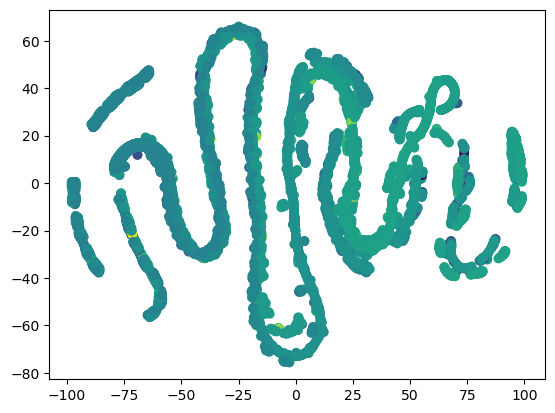

In [6]:
# --! latent space diagnostic --!

# --! collect various metrics of latent space
past_mean_vc = back[:, :, 0].mean(dim=1)
past_mean_dc = back[:, :, 1].mean(dim=1)
future_mean_vc = fore[:, :, 0].mean(dim=1)
future_mean_dc = fore[:, :, 1].mean(dim=1)
future_mean_vc_sign = future_mean_vc > 0

# --! fit latent space into t-distributed stochastic neighbor embedding (TSNE)
y = TSNE().fit_transform(z_np)

# --! display distribution and color it using one of the above metrics
plt.figure()
plt.scatter(
    y[:,0],
    y[:,1],
    c=past_mean_vc
)
plt.show()

In [7]:
# --! cluster encoded latent space using KMeans --!

ncluster = 3
kmeans = KMeans(n_clusters=ncluster).fit(z_np)

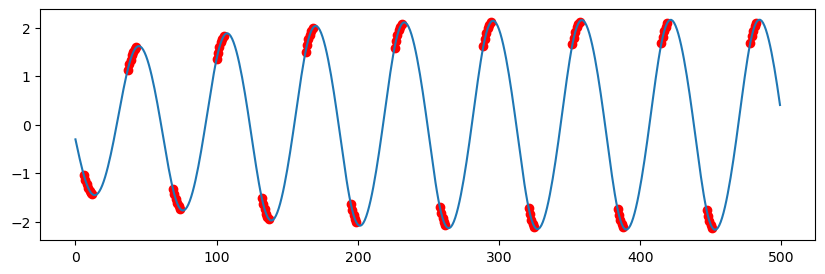

In [20]:
# --! plot discovered clusters ontop of data --!

t0 = 2140
t1 = t0 + 500

#t0 = 0
#t1 = t0 + 500

test_data = data[t0:t1, 48, 0]
test_time = np.arange(len(test_data))
test_kmeans_idx = kmeans.labels_==0
test_kmeans_idx = test_kmeans_idx[t0:t1]

plt.figure(figsize=(10,3))
plt.plot(test_time, test_data)
plt.scatter(test_time[test_kmeans_idx], test_data[test_time[test_kmeans_idx]], color='red')
plt.show()

In [9]:
prob = np.zeros((ncluster, ncluster))

# --! extract labels for one trajectory to avoid artificial bumps on transitions between trajectories
#one_traj_nsample = 1800
labels = kmeans.labels_[2140:2640]

for i in range(len(labels)-1):
    prob[labels[i], labels[i+1]] += 1

prob /= prob.sum(axis=1, keepdims=True)
print(prob)

# --! compute residence time in each cluster as a list of tuples (cluster index, residence)
residence = [(key, sum(1 for _ in group)) for key, group in groupby(labels)]

# --! sort residence list in descending order, such that
# --! short transition corridors move to the end of this list
sorted_residence = sorted(residence, key=lambda x: x[1])[::-1]
print(sorted_residence)

print(sorted_residence[-1][0])

[[0.82417582 0.08791209 0.08791209]
 [0.03921569 0.96078431 0.        ]
 [0.03921569 0.         0.96078431]]
[(np.int32(1), 27), (np.int32(2), 26), (np.int32(2), 26), (np.int32(1), 26), (np.int32(2), 26), (np.int32(1), 26), (np.int32(2), 26), (np.int32(1), 26), (np.int32(2), 26), (np.int32(1), 26), (np.int32(1), 26), (np.int32(2), 25), (np.int32(2), 25), (np.int32(1), 25), (np.int32(2), 24), (np.int32(1), 17), (np.int32(0), 7), (np.int32(0), 7), (np.int32(0), 6), (np.int32(0), 6), (np.int32(0), 6), (np.int32(0), 6), (np.int32(0), 6), (np.int32(0), 6), (np.int32(0), 6), (np.int32(1), 6), (np.int32(0), 5), (np.int32(0), 5), (np.int32(0), 5), (np.int32(0), 5), (np.int32(0), 5), (np.int32(0), 5), (np.int32(0), 5)]
0


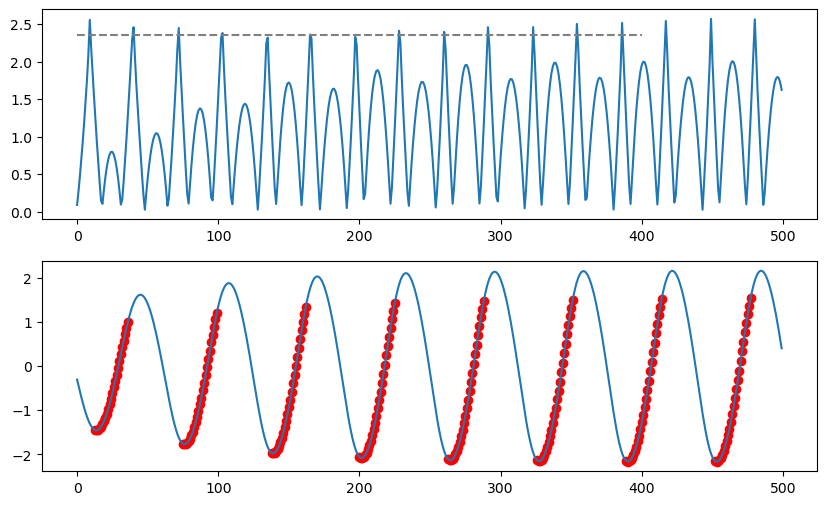

In [10]:
# --! compute proximity to nominal regions --!

centers = kmeans.cluster_centers_
rho = cdist(z_np, centers, metric='euclidean')
rho_nom = np.minimum(rho[:, sorted_residence[0][0]], rho[:, sorted_residence[1][0]])

rho_star = np.percentile(rho_nom, 90)

plt.figure(figsize=(10,6))
plt.subplot(2,1,1)
#plt.title('Proximity to nominal regions')
plt.plot(rho_nom[2140:2640])
plt.plot([0, 400], [rho_star, rho_star], color='gray', linestyle='dashed', label=r'$\rho^{\star}$')
#plt.legend()

plt.subplot(2,1,2)
plt.plot(test_time, test_data)
plt.scatter(test_time[test_kmeans_idx], test_data[test_time[test_kmeans_idx]], color='red')

plt.show()

In [21]:
datasaved = True
if datasaved:

    lbls = test_data[test_time[test_kmeans_idx]]
    i_lbls = test_time[test_kmeans_idx]

    lbls = np.expand_dims(lbls, 0)
    lbls = np.expand_dims(lbls, -1)
    i_lbls = np.expand_dims(i_lbls, 0)
    i_lbls = np.expand_dims(i_lbls, -1)

    traj  = np.expand_dims(test_data,  0)
    traj  = np.expand_dims(traj, -1)

    step = np.arange(traj.shape[1]).reshape(1, -1, 1)
    savedata = np.concatenate([
        step,
        traj], axis=2)
    util_data.write_datafile(f'{result_dir}/vanderpol_curves_cluster', savedata, delim=' ')

    savedata = np.concatenate([
        i_lbls,
        lbls], axis=2)
    util_data.write_datafile(f'{result_dir}/vanderpol_labels_cluster', savedata, delim=' ')

    print(f'[note]: regime discovery saved')

[note]: regime discovery saved
